# 04. Thí nghiệm và đánh giá

**Mục tiêu:** so sánh baseline B2 (notebook 03) với các mô hình bắt được đường cong của tốc độ, một cách công bằng; kiểm định chênh lệch; phân tích ca lỗi và trả lời câu hỏi nghiên cứu.

**Đầu vào:** `data/processed/flight_level.csv`, kết quả notebook 03 (MAE của B2 = 1,48 Wh)

**Đầu ra:** `reports/experiment_results.csv`, hình `exp_*.png` trong `reports/figures/`

## 0. Chuẩn bị

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedKFold, KFold, GridSearchCV

# Gốc repo: chạy notebook từ thư mục notebooks/ hay từ gốc đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

In [2]:
df = pd.read_csv(PROCESSED / "flight_level.csv")
FEATURE = ["speed", "payload", "altitude"]
X = df[FEATURE]
y = df["E_Wh"]
print("Kích thước:", df.shape)

Kích thước: (192, 11)


## 1. Thiết kế công bằng

- [x] Cùng data, cùng fold, cùng seed cho mọi mô hình

Giống hệt notebook 03:
- **Cùng dữ liệu:** 192 chuyến, cùng 3 feature biết trước khi bay (`speed`, `payload`, `altitude`). Không thêm cự ly, để so sánh đúng với B2 và với nhóm NCKH.
- **Cùng cách chia:** `RepeatedKFold` 5 fold × 10 lần lặp, seed 301 → 50 lần đánh giá. Danh sách 50 cách chia được tạo **một lần** rồi dùng lại cho mọi mô hình, nên mô hình nào cũng thi đúng 50 đề giống nhau.
- **Cùng thước đo:** MAE, RMSE, R² (bài toán hồi quy, target là số Wh).

In [3]:
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
CHIA = list(cv.split(X))   # 50 cặp (train, test), dùng chung cho mọi mô hình
print("Số lần đánh giá:", len(CHIA))
print("Mỗi lần: train", len(CHIA[0][0]), "chuyến, test", len(CHIA[0][1]), "chuyến")

Số lần đánh giá: 50
Mỗi lần: train 153 chuyến, test 39 chuyến


## 2. Mô hình so sánh

- [x] Random Forest / Gradient Boosting so với baseline tốt nhất

**Vì sao chọn các mô hình này?** Notebook 03 cho thấy điểm yếu chính của B2 là phần dư **hình chữ U theo tốc độ**: quan hệ tốc độ – năng lượng là đường cong (notebook 02, mục 3.2), mà B2 chỉ vẽ được đường thẳng. Mỗi mô hình dưới đây là một cách khác nhau để bắt đường cong đó:

| Mô hình | Cách bắt đường cong | Ưu | Nhược |
|---|---|---|---|
| B2. Hồi quy tuyến tính | Không bắt (mốc so sánh) | Dễ giải thích | Bỏ sót đường cong |
| M1. Hồi quy + speed² | Thêm cột speed² để đường thẳng thành **parabol** theo tốc độ | Vẫn có hệ số để đọc | Phải tự đoán dạng cong |
| M2. Random Forest | Trung bình của nhiều **cây quyết định**, mỗi cây chia dữ liệu thành các ô | Tự tìm dạng cong và tương tác | Khó giải thích, không đoán được ngoài vùng đã thấy |
| M3. Gradient Boosting | Nhiều cây nhỏ, cây sau **sửa lỗi** cây trước | Thường chính xác nhất với bảng dữ liệu | Như RF |

**Chọn tham số không "nhìn trộm" đề thi:** RF và GB có tham số cần chọn (độ sâu cây, số mẫu tối thiểu ở lá). Em dùng `GridSearchCV` **bên trong** mỗi lần train: tham số được chọn bằng một vòng 5-fold nhỏ chỉ trên khoảng 153 chuyến train, rồi mới đoán khoảng 39 chuyến test. Chuyến test không bao giờ được dùng để chọn tham số (gọi là *nested cross-validation*).

In [4]:
def them_speed2(X):
    """Thêm cột speed² vào sau 3 feature."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([X, X[:, 0] ** 2])

cv_trong = KFold(n_splits=5, shuffle=True, random_state=SEED)   # vòng chọn tham số, chỉ trên tập train

mo_hinh = {
    "B2. Hồi quy tuyến tính": LinearRegression(),
    "M1. Hồi quy + speed²": make_pipeline(FunctionTransformer(them_speed2), LinearRegression()),
    "M2. Random Forest": GridSearchCV(
        RandomForestRegressor(n_estimators=200, random_state=SEED),
        {"min_samples_leaf": [1, 3, 5]}, cv=cv_trong, scoring="neg_mean_absolute_error", n_jobs=-1),
    "M3. Gradient Boosting": GridSearchCV(
        GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=SEED),
        {"max_depth": [1, 2, 3]}, cv=cv_trong, scoring="neg_mean_absolute_error", n_jobs=-1),
}

**Chạy 50 lần đánh giá cho mỗi mô hình.** Mỗi lần: học trên train, đoán test, ghi lại MAE, RMSE, R². Đồng thời lưu dự đoán của từng chuyến (mỗi chuyến được đoán 10 lần, mỗi lần bởi một mô hình chưa thấy nó; lấy trung bình) để phân tích lỗi ở mục 4. Ô này chạy khoảng 2–3 phút vì RF và GB phải chọn tham số 50 lần.

In [5]:
diem = {}       # diem[tên][thước đo] = mảng 50 giá trị
du_doan = {}    # dự đoán out-of-fold trung bình cho từng chuyến
tham_so = {}    # tham số được chọn ở mỗi lần (RF, GB)

for ten, m in mo_hinh.items():
    mae, rmse, r2, chon = [], [], [], []
    tong = np.zeros(len(y))
    dem = np.zeros(len(y))
    for tr, te in CHIA:
        mm = clone(m).fit(X.iloc[tr], y.iloc[tr])
        p = mm.predict(X.iloc[te])
        sai = y.iloc[te].to_numpy() - p
        mae.append(np.abs(sai).mean())
        rmse.append(np.sqrt((sai ** 2).mean()))
        r2.append(1 - (sai ** 2).sum() / ((y.iloc[te] - y.iloc[te].mean()) ** 2).sum())
        tong[te] += p
        dem[te] += 1
        if hasattr(mm, "best_params_"):
            chon.append(str(mm.best_params_))
    diem[ten] = {"MAE": np.array(mae), "RMSE": np.array(rmse), "R2": np.array(r2)}
    du_doan[ten] = tong / dem
    if chon:
        tham_so[ten] = pd.Series(chon).value_counts().to_dict()

tham_so

{'M2. Random Forest': {"{'min_samples_leaf': 1}": 50},
 'M3. Gradient Boosting': {"{'max_depth': 2}": 45, "{'max_depth': 3}": 5}}

In [6]:
bang = pd.DataFrame({
    ten: {"MAE_tb": d["MAE"].mean(), "RMSE_tb": d["RMSE"].mean(), "R2_tb": d["R2"].mean(),
          "MAE_sd": d["MAE"].std(), "RMSE_sd": d["RMSE"].std(), "R2_sd": d["R2"].std()}
    for ten, d in diem.items()
}).T
bang["MAE / E trung bình"] = (bang["MAE_tb"] / y.mean() * 100).round(1).astype(str) + "%"
bang["Giảm MAE so với B2"] = ((1 - bang["MAE_tb"] / bang.loc["B2. Hồi quy tuyến tính", "MAE_tb"]) * 100).round(0).astype(int).astype(str) + "%"

hien = pd.DataFrame({
    "MAE (Wh)": bang["MAE_tb"].round(2).astype(str) + " ± " + bang["MAE_sd"].round(2).astype(str),
    "RMSE (Wh)": bang["RMSE_tb"].round(2).astype(str) + " ± " + bang["RMSE_sd"].round(2).astype(str),
    "R²": bang["R2_tb"].round(2).astype(str) + " ± " + bang["R2_sd"].round(2).astype(str),
    "MAE / E trung bình": bang["MAE / E trung bình"],
    "Giảm MAE so với B2": bang["Giảm MAE so với B2"],
})
bang.drop(columns=["MAE / E trung bình", "Giảm MAE so với B2"]).round(4).to_csv(
    ROOT / "reports" / "experiment_results.csv", encoding="utf-8-sig")
hien

,MAE (Wh),RMSE (Wh),R²,MAE / E trung bình,Giảm MAE so với B2
B2. Hồi quy tuyến tính,1.48 ± 0.17,1.94 ± 0.46,0.83 ± 0.07,6.9%,0%
M1. Hồi quy + speed²,0.85 ± 0.17,1.38 ± 0.55,0.91 ± 0.07,4.0%,43%
M2. Random Forest,0.88 ± 0.21,1.54 ± 0.56,0.88 ± 0.08,4.1%,40%
M3. Gradient Boosting,0.83 ± 0.19,1.41 ± 0.55,0.9 ± 0.07,3.9%,44%


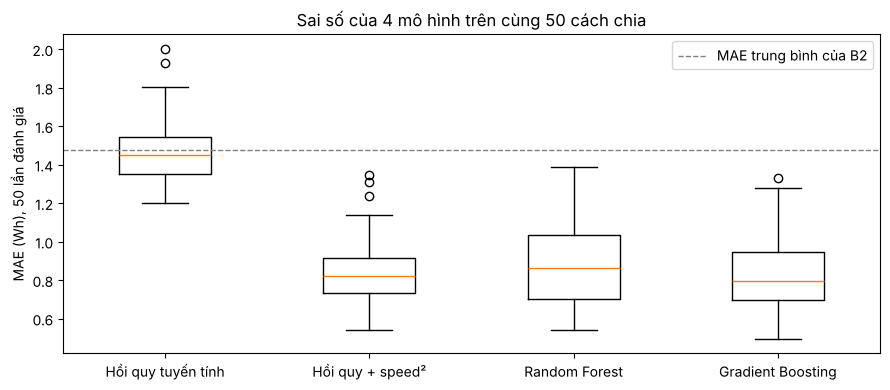

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([diem[t]["MAE"] for t in diem])
ax.set_xticklabels([t.split(". ")[1] for t in diem])
ax.axhline(diem["B2. Hồi quy tuyến tính"]["MAE"].mean(), color="gray", ls="--", lw=1, label="MAE trung bình của B2")
ax.set_ylabel("MAE (Wh), 50 lần đánh giá")
ax.set_title("Sai số của 4 mô hình trên cùng 50 cách chia")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "exp_mae.png", dpi=150)
plt.show()

**Kết luận** (đọc số ở bảng và hình trên):
- **Cả 3 mô hình mới đều tốt hơn hẳn B2:** MAE giảm từ khoảng 1,48 Wh xuống khoảng 0,83–0,88 Wh (giảm khoảng 40–44%), R² tăng từ 0,83 lên khoảng 0,88–0,91. Sai số giờ chỉ còn khoảng 4% năng lượng trung bình.
- **M1 (hồi quy + speed²) và M3 (Gradient Boosting) gần như ngang nhau** (MAE khoảng 0,85 và 0,83 Wh). M2 (Random Forest) kém hơn một chút, RMSE cao hơn.
- Điều này xác nhận chẩn đoán ở notebook 03: **phần lớn sai số của B2 đến từ đường cong của tốc độ.** Chỉ cần thêm một cột speed² là đã lấy lại gần hết phần chính xác mà mô hình cây phức tạp đạt được.
- Tham số được chọn: RF chọn `min_samples_leaf = 1` cả 50 lần; GB chọn `max_depth = 2` hầu hết các lần (cây nông, đủ để bắt tương tác giữa 2 biến).

## 3. Kiểm định

- [x] Paired t-test hoặc bootstrap CI cho chênh lệch MAE
- [x] Khác biệt có ý nghĩa không?

**Vì sao "paired" (theo cặp)?** Ở mỗi lần trong 50 lần, các mô hình thi **cùng một đề**. Đề khó thì mô hình nào cũng sai nhiều, đề dễ thì cùng sai ít. So theo cặp (lấy MAE của B2 trừ MAE của mô hình kia **trong cùng một lần**) sẽ loại được độ khó của đề, chỉ còn lại chênh lệch thật giữa 2 mô hình.

**Vì sao phải "hiệu chỉnh"?** 50 lần đánh giá **không độc lập**: các tập train chồng lên nhau rất nhiều (2 tập train bất kỳ dùng chung phần lớn chuyến bay). t-test thường sẽ tưởng có 50 bằng chứng độc lập và cho p-value nhỏ quá mức. Nadeau & Bengio (2003) đề xuất phóng to phương sai lên theo tỷ lệ test/train: thay 1/k bằng (1/k + n_test/n_train). Đây là cách chuẩn khi so 2 mô hình bằng cross-validation lặp lại.

**Giả thuyết:** H0: hai mô hình có MAE như nhau. Nếu p < 0,05 → bác bỏ H0, chênh lệch có thật.

In [8]:
def t_test_hieu_chinh(mae_a, mae_b, n_train, n_test):
    """Paired t-test có hiệu chỉnh Nadeau-Bengio cho cross-validation lặp lại.
    Trả về: chênh lệch MAE trung bình (a - b), t, p-value, số lần b thắng a."""
    d = mae_a - mae_b
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return d.mean(), t, p, int((d > 0).sum())

n_test = len(CHIA[0][1])
n_train = len(CHIA[0][0])

cap_so = [
    ("B2. Hồi quy tuyến tính", "M1. Hồi quy + speed²"),
    ("B2. Hồi quy tuyến tính", "M2. Random Forest"),
    ("B2. Hồi quy tuyến tính", "M3. Gradient Boosting"),
    ("M1. Hồi quy + speed²", "M3. Gradient Boosting"),
    ("M1. Hồi quy + speed²", "M2. Random Forest"),
]
kiem_dinh = []
for a, b in cap_so:
    chenh, t, p, thang = t_test_hieu_chinh(diem[a]["MAE"], diem[b]["MAE"], n_train, n_test)
    kiem_dinh.append({"So sánh": f"{a.split('.')[0]} − {b.split('.')[0]}", "Chênh MAE (Wh)": round(chenh, 3),
                      "t": round(t, 2), "p-value": f"{p:.1e}", "Số lần vế sau thắng (/50)": thang,
                      "Kết luận (α = 0,05)": "Khác biệt có thật" if p < 0.05 else "Không đủ bằng chứng khác nhau"})
pd.DataFrame(kiem_dinh)

,So sánh,Chênh MAE (Wh),t,p-value,Số lần vế sau thắng (/50),"Kết luận (α = 0,05)"
0,B2 − M1,0.629,9.24,2.6e-12,50,Khác biệt có thật
1,B2 − M2,0.596,6.69,2.0e-08,50,Khác biệt có thật
2,B2 − M3,0.645,8.57,2.6e-11,50,Khác biệt có thật
3,M1 − M3,0.017,0.27,7.9e-01,33,Không đủ bằng chứng khác nhau
4,M1 − M2,-0.032,-0.40,6.9e-01,24,Không đủ bằng chứng khác nhau


**Kết luận:**
- **B2 so với M1, M2, M3:** cả 3 mô hình mới thắng B2 ở **cả 50/50 lần**, chênh khoảng 0,6 Wh, p-value rất nhỏ (< 0,001) **kể cả sau khi đã hiệu chỉnh**. Kết luận chắc chắn: bắt được đường cong của tốc độ giúp dự đoán tốt hơn thật sự, không phải do may.
- **M1 so với M3 (GB):** chênh chỉ khoảng 0,02 Wh, p ≈ 0,8. **Không đủ bằng chứng** nói GB tốt hơn hồi quy + speed².
- **M1 so với M2 (RF):** p ≈ 0,7, cũng không khác nhau có ý nghĩa.
- Nghĩa là: 3 mô hình mới chính xác **ngang nhau** về mặt thống kê. Muốn chọn mô hình thì phải dựa vào tiêu chí khác: dễ giải thích và an toàn khi gặp cài đặt mới (mục 4).

## 4. Ca lỗi

- [x] Mô hình sai nhiều nhất ở chuyến nào, điều kiện nào? Vì sao?
- [x] Thử bỏ hẳn một mức tốc độ hoặc độ cao: mô hình nào ngoại suy tốt hơn?

### 4.1 Hình chữ U của B2 đã hết chưa?

Phần dư = năng lượng thật − dự đoán (dùng dự đoán out-of-fold ở mục 2). Phần dư **dương** = đoán **thiếu**.

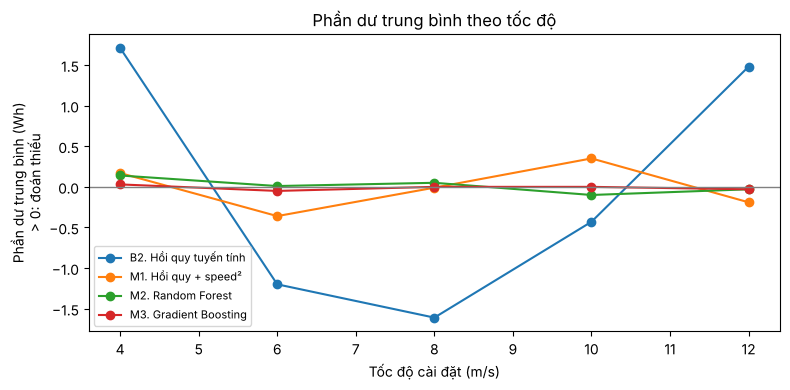

speed,4.0,6.0,8.0,10.0,12.0
B2. Hồi quy tuyến tính,1.71,-1.20,-1.61,-0.43,1.48
M1. Hồi quy + speed²,0.17,-0.36,-0.01,0.35,-0.19
M2. Random Forest,0.14,0.01,0.05,-0.10,-0.03
M3. Gradient Boosting,0.03,-0.05,0.00,0.00,-0.03


In [9]:
phan_du = pd.DataFrame({ten: y - p for ten, p in du_doan.items()})
theo_toc_do = phan_du.groupby(df["speed"]).mean().round(2)

fig, ax = plt.subplots(figsize=(8, 4))
for ten in theo_toc_do:
    ax.plot(theo_toc_do.index, theo_toc_do[ten], marker="o", label=ten)
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("Tốc độ cài đặt (m/s)")
ax.set_ylabel("Phần dư trung bình (Wh)\n> 0: đoán thiếu")
ax.set_title("Phần dư trung bình theo tốc độ")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "exp_phan_du_toc_do.png", dpi=150)
plt.show()
theo_toc_do.T

**Kết luận:** B2 có hình chữ U rõ (đoán thiếu khoảng +1,7 Wh ở 4 m/s và +1,5 Wh ở 12 m/s, đoán dư khoảng −1,6 Wh ở 8 m/s). Ở cả 3 mô hình mới, phần dư trung bình theo tốc độ đều về gần 0 (|phần dư| ≤ khoảng 0,4 Wh). **Hình chữ U đã được sửa.**

### 4.2 Chuyến nào vẫn bị sai nhiều?

Với drone, **đoán thiếu** là kiểu sai nguy hiểm: kế hoạch tưởng pin đủ mà thực tế không đủ. Đếm số chuyến bị đoán thiếu hơn 2 Wh (khoảng 10% năng lượng trung bình) và xem các chuyến sai nặng nhất.

In [10]:
ca_loi = pd.DataFrame({
    "Số chuyến đoán thiếu > 2 Wh": (phan_du > 2).sum(),
    "Trong đó là R6": ((phan_du > 2) & (df["route"] == "R6").to_numpy()[:, None]).sum(),
    "Đoán thiếu nặng nhất (Wh)": phan_du.max().round(1),
})
ca_loi

,Số chuyến đoán thiếu > 2 Wh,Trong đó là R6,Đoán thiếu nặng nhất (Wh)
B2. Hồi quy tuyến tính,26,5,13.6
M1. Hồi quy + speed²,7,5,12.2
M2. Random Forest,7,5,12.4
M3. Gradient Boosting,7,5,11.9


In [11]:
TOT_NHAT = "M3. Gradient Boosting"
xem = df[["flight", "route", "speed", "payload", "altitude", "E_Wh"]].copy()
xem["du_doan_M1"] = du_doan["M1. Hồi quy + speed²"].round(1)
xem["du_doan_M3"] = du_doan[TOT_NHAT].round(1)
xem["phan_du_M3"] = phan_du[TOT_NHAT].round(1)
xem.reindex(phan_du[TOT_NHAT].abs().sort_values(ascending=False).index).head(8).round(1)

,flight,route,speed,payload,altitude,E_Wh,du_doan_M1,du_doan_M3,phan_du_M3
188,272,R6,4.0,250.0,50,37.7,25.6,25.8,11.9
184,268,R6,6.0,500.0,25,28.7,20.6,19.5,9.1
187,271,R6,10.0,0.0,25,18.4,12.4,13.2,5.2
185,269,R6,12.0,500.0,25,19.9,16.8,15.4,4.5
186,270,R6,10.0,250.0,75,24.0,19.8,20.3,3.7
134,199,R1,4.0,250.0,50,24.7,25.9,28.2,-3.4
68,129,R1,12.0,500.0,75,24.8,22.0,21.9,2.9
65,126,R1,4.0,500.0,100,36.2,33.0,33.4,2.8


In [12]:
print("MAE theo route (Wh):")
phan_du.abs().groupby(df["route"].where(df["route"] == "R6", "R1–R5")).mean().round(2)

MAE theo route (Wh):


,B2. Hồi quy tuyến tính,M1. Hồi quy + speed²,M2. Random Forest,M3. Gradient Boosting
route,,,,
R1–R5,1.33,0.69,0.67,0.64
R6,6.85,6.71,7.00,6.89


**Kết luận:**
- Số chuyến bị đoán thiếu hơn 2 Wh giảm từ **26 (B2) xuống 7** ở cả 3 mô hình mới.
- Nhưng **5/7 chuyến đó là R6**, và cả 5 chuyến R6 vẫn bị đoán thiếu nặng (khoảng 3,5–12 Wh) ở **mọi** mô hình. MAE trên R6 vẫn khoảng 7 Wh, trong khi R1–R5 chỉ khoảng 0,7 Wh.
- Lý do đã biết từ notebook 03 (mục 4.4): R6 bay xa gần gấp đôi R1 (khoảng 836 m so với 473 m), mà cả 4 mô hình đều chỉ biết tốc độ, tải, độ cao. **Mô hình phức tạp hơn không thay được thông tin bị thiếu.** Muốn sửa R6 phải thêm cự ly (notebook 03: MAE của R6 giảm từ 6,8 xuống 2,8 Wh khi thêm cự ly).
- Chuyến sai nặng nhất vẫn là **272** (R6, 4 m/s, 250 g, 50 m): bay chậm trên đường dài nhất nên tốn nhất cả bộ dữ liệu (37,7 Wh).

### 4.3 Ngoại suy: đoán cho cài đặt chưa từng bay

Câu hỏi thực tế: nếu người vận hành cài một mức tốc độ hoặc độ cao **chưa có trong dữ liệu** thì mô hình còn dùng được không? Thử bằng cách **bỏ hẳn một mức** khi train, rồi đoán đúng mức đó. Chọn 2 mức ở **mép** (thấp nhất, cao nhất) của tốc độ và độ cao, vì đó là chỗ phải ngoại suy thật sự.

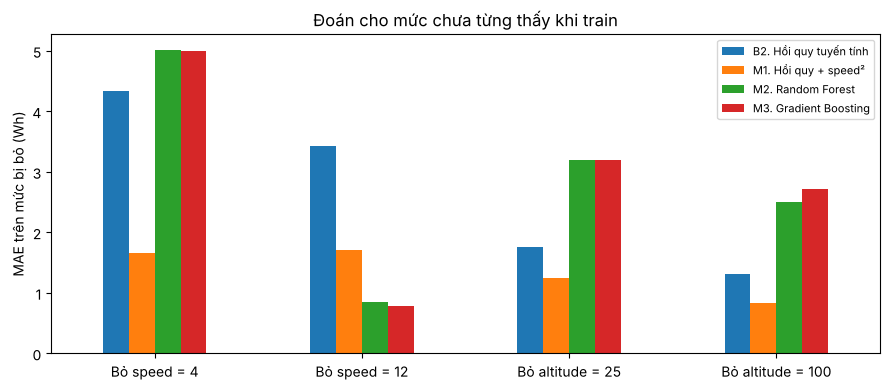

,B2. Hồi quy tuyến tính,M1. Hồi quy + speed²,M2. Random Forest,M3. Gradient Boosting
Bỏ speed = 4,4.34,1.66,5.02,4.99
Bỏ speed = 12,3.43,1.71,0.85,0.78
Bỏ altitude = 25,1.76,1.25,3.19,3.20
Bỏ altitude = 100,1.31,0.84,2.50,2.72


In [13]:
ngoai_suy = {}
for cot, muc in [("speed", 4), ("speed", 12), ("altitude", 25), ("altitude", 100)]:
    tr = df[cot] != muc
    te = ~tr
    ngoai_suy[f"Bỏ {cot} = {muc}"] = {
        ten: np.abs(y[te] - clone(m).fit(X[tr], y[tr]).predict(X[te])).mean()
        for ten, m in mo_hinh.items()
    }
ngoai_suy = pd.DataFrame(ngoai_suy).T.round(2)

ax = ngoai_suy.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("MAE trên mức bị bỏ (Wh)")
ax.set_title("Đoán cho mức chưa từng thấy khi train")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "exp_ngoai_suy.png", dpi=150)
plt.show()
ngoai_suy

**Kết luận:**
- **Bỏ tốc độ 4 m/s, độ cao 25 m hoặc 100 m:** RF và GB sai nhiều nhất (MAE khoảng 2,5–5 Wh), còn tệ hơn cả B2. Lý do: mô hình cây chỉ chia dữ liệu thành các ô và **đoán bằng giá trị của ô gần nhất đã thấy**. Gặp mức mới ở mép, cây đoán như mức kế bên, không biết "đi tiếp" theo xu hướng. M1 sai ít nhất ở cả 3 trường hợp (khoảng 0,8–1,7 Wh), vì công thức parabol tự kéo dài xu hướng ra ngoài.
- **Bỏ tốc độ 12 m/s:** ngược lại, RF và GB tốt nhất (khoảng 0,8 Wh). Lý do là trường hợp đặc biệt: ở 12 m/s drone thật ra chỉ bay khoảng 10,7 m/s (notebook 02, mục 3.2), nên năng lượng gần bằng mức 10 m/s, và "đoán như mức kế bên" tình cờ đúng.
- Kết luận chung: **M1 an toàn hơn khi gặp cài đặt mới**, nhất là theo hướng tốn nhiều năng lượng (bay chậm, bay cao), đúng là hướng nguy hiểm cho pin.

### 4.4 Đọc hệ số của M1

M1 vẫn là hồi quy nên đọc được hệ số như B2. Fit trên toàn bộ 192 chuyến, kèm khoảng tin cậy 95%:

In [14]:
A = np.column_stack([np.ones(len(df)), df["speed"], df["speed"] ** 2, df["payload"], df["altitude"]])
he_so, *_ = np.linalg.lstsq(A, y, rcond=None)
sai = y - A @ he_so
n, k = A.shape
se = np.sqrt(np.diag((sai @ sai) / (n - k) * np.linalg.inv(A.T @ A)))
t_crit = stats.t.ppf(0.975, n - k)
pd.DataFrame({"hệ số": he_so, "CI 95% dưới": he_so - t_crit * se, "CI 95% trên": he_so + t_crit * se},
             index=["hằng số", "speed", "speed²", "payload (mỗi 1 g)", "altitude (mỗi 1 m)"]).round(4)

,hệ số,CI 95% dưới,CI 95% trên
hằng số,32.1960,30.2911,34.1009
speed,-4.1944,-4.6982,-3.6905
speed²,0.1969,0.1656,0.2282
payload (mỗi 1 g),0.0081,0.0071,0.0091
altitude (mỗi 1 m),0.1050,0.0976,0.1124


In [15]:
v_tot_nhat = -he_so[1] / (2 * he_so[2])   # đỉnh parabol: chỗ đạo hàm bằng 0
print(f"Tốc độ cài đặt tốn ít năng lượng nhất theo M1: khoảng {v_tot_nhat:.1f} m/s")
for v in [4, 6, 8, 10, 12]:
    doi = he_so[1] * (v - 4) + he_so[2] * (v ** 2 - 16)
    print(f"  {v:>2} m/s so với 4 m/s: {doi:+.1f} Wh")

Tốc độ cài đặt tốn ít năng lượng nhất theo M1: khoảng 10.7 m/s
   4 m/s so với 4 m/s: +0.0 Wh
   6 m/s so với 4 m/s: -4.5 Wh
   8 m/s so với 4 m/s: -7.3 Wh
  10 m/s so với 4 m/s: -8.6 Wh
  12 m/s so với 4 m/s: -8.4 Wh


**Kết luận:**
- Hệ số `speed` âm và `speed²` dương → năng lượng theo tốc độ là **parabol úp lên**: giảm nhanh lúc đầu, chậm dần, rồi chững lại. Đỉnh parabol ở khoảng **10,7 m/s**, khớp với tốc độ thật lớn nhất drone đạt được (notebook 02: cài 12 m/s chỉ bay khoảng 10,7 m/s). Không nên hiểu là "bay nhanh hơn 10,7 m/s sẽ tốn hơn"; đúng hơn là **cài trên khoảng 10 m/s không tiết kiệm thêm**.
- Từ 4 lên 10 m/s tiết kiệm khoảng 8,6 Wh mỗi chuyến.
- Hệ số `payload` (+0,0081 Wh/g, tức +0,8 Wh mỗi 100 g) và `altitude` (+0,105 Wh/m, tức +2,6 Wh mỗi 25 m) **giữ nguyên như B2**: thêm speed² không làm thay đổi tác động của tải và độ cao, nhờ 3 feature độc lập nhau.

## 5. Kết luận

- [x] Chọn mô hình nào? Trade-off: độ chính xác, dễ giải thích, độ phức tạp
- [x] Trả lời câu hỏi nghiên cứu

| Tiêu chí | B2 | M1. Hồi quy + speed² | M2. RF | M3. GB |
|---|---|---|---|---|
| MAE (Wh) | 1,48 | khoảng 0,85 | khoảng 0,88 | khoảng 0,83 |
| Thắng B2 có ý nghĩa? | | Có (p < 0,001) | Có | Có |
| Khác M1 có ý nghĩa? | | | Không (p ≈ 0,7) | Không (p ≈ 0,8) |
| Ngoại suy ở mép (4 m/s, 25 m, 100 m) | Trung bình | **Tốt nhất** | Kém | Kém |
| Đọc được tác động từng yếu tố? | Có | **Có** | Không | Không |
| Thời gian chạy | Tức thì | Tức thì | Vài phút | Khoảng 1 phút |

**Chọn M1 (hồi quy tuyến tính + speed²).** Chính xác ngang Gradient Boosting (khác biệt không có ý nghĩa thống kê), nhưng giải thích được bằng hệ số và an toàn hơn khi gặp cài đặt chưa từng bay. Với bài toán lên kế hoạch pin, hai điểm sau quan trọng hơn chênh lệch 0,02 Wh.

**Trả lời câu hỏi nghiên cứu:** chỉ với 3 thông số cài trước khi bay (tốc độ, tải, độ cao), có thể dự đoán năng lượng của một chuyến giao hàng với sai số trung bình khoảng **0,85 Wh (khoảng 4% năng lượng trung bình)**, R² khoảng 0,91. Tốc độ có tác động **cong** (tiết kiệm tới khoảng 10 m/s rồi chững lại), tải và độ cao có tác động gần **tuyến tính**.

**Hạn chế:** mô hình nào cũng đoán thiếu cả 5 chuyến R6 (bay xa gần gấp đôi), vì không có thông tin cự ly. Khi dùng thật cho đường bay khác R1 cần thêm cự ly làm feature, và nên lập kế hoạch pin theo cận trên của khoảng dự đoán chứ không theo số đoán.

## Ghi chú cho báo cáo

**Bước này tìm ra gì** (dùng cho D4):

1. **Thiết kế:** cùng 192 chuyến, 3 feature, 50 cách chia (5-fold × 10, seed 301) như notebook 03. Tham số RF/GB chọn bằng vòng 5-fold bên trong tập train (nested CV).
2. **Kết quả:** M1 (hồi quy + speed²) MAE khoảng 0,85 Wh, RF khoảng 0,88, GB khoảng 0,83, so với B2 1,48 Wh. Giảm khoảng 40–44%. R² từ 0,83 lên khoảng 0,91.
3. **Kiểm định** (paired t-test hiệu chỉnh Nadeau–Bengio): cả 3 thắng B2 50/50 lần, p < 0,001. M1, RF, GB không khác nhau có ý nghĩa (p ≈ 0,7–0,8).
4. **Ca lỗi:** hình chữ U theo tốc độ đã hết. Chuyến đoán thiếu > 2 Wh giảm từ 26 xuống 7, trong đó 5 là R6; R6 vẫn bị đoán thiếu ở mọi mô hình do thiếu cự ly.
5. **Ngoại suy:** bỏ mức 4 m/s, 25 m, 100 m khi train thì RF/GB sai nhiều nhất, M1 sai ít nhất. Ngoại lệ 12 m/s do drone không đạt tốc độ cài đặt.
6. **Chọn M1:** chính xác ngang GB, giải thích được, ngoại suy an toàn hơn. Tốc độ tiết kiệm nhất khoảng 10–11 m/s.

**Hình cho báo cáo:** `exp_mae.png`, `exp_phan_du_toc_do.png`, `exp_ngoai_suy.png`. **Bảng:** `reports/experiment_results.csv`.